# 04: Machine Learning Analysis - Classification & Regression Pipelines
## Holistic Health and Lifestyle Score Dataset | Multi-Objective ML & Predictive Modeling

## Question 1: Physical Activity and Overall Health Score
### _In this section, we investigate our first research question: exploring whether higher physical activity is positively associated with the overall health score. We load the dataset, isolate the relevant variables, compute correlation, and generate a scatter plot with a trendline to visualize the association._

Correlation between Physical Activity and Overall Health Score: 0.1460


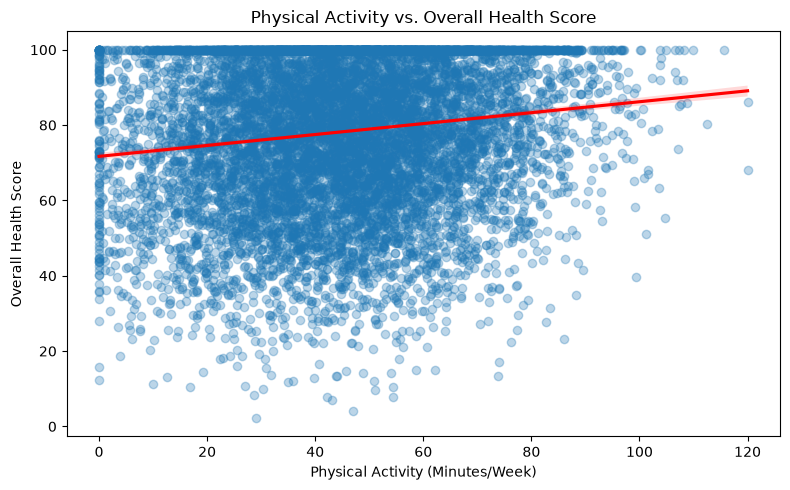

In [2]:
# Import required libraries for data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Setup directories for saved visuals
visuals_dir = Path("../visuals")
visuals_dir.mkdir(parents=True, exist_ok=True)

# Load the cleaned dataset
df = pd.read_csv("../cleaned_datasets/holistic_health_lifestyle_cleaned.csv")

# Calculate Pearson correlation coefficient between Physical Activity and Overall Health Score
pa_corr = df['Physical_Activity'].corr(df['Overall_Health_Score'])
print(f"Correlation between Physical Activity and Overall Health Score: {pa_corr:.4f}")

# Generate a scatter plot with a regression trendline
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df, 
    x='Physical_Activity', 
    y='Overall_Health_Score', 
    scatter_kws={'alpha': 0.3}, 
    line_kws={'color': 'red'}
)
plt.title("Physical Activity vs. Overall Health Score")
plt.xlabel("Physical Activity (Minutes/Week)")
plt.ylabel("Overall Health Score")
plt.tight_layout()

# Save the visualization
plt.savefig(visuals_dir / "q1_physical_activity_vs_health.png", dpi=300)
plt.show()

### Correlation between Physical Activity and Overall Health Score: 0.1460

Outcome: A weak positive correlation (r = 0.146) was observed between physical activity and the overall health score, supporting the directional hypothesis while noting a moderate linear association within this synthetic dataset.

## Question 2: Nutrition Score and Overall Health Score

### _This section addresses research question 2: examining whether higher nutrition scores are positively associated with the overall health score. We evaluate the statistical relationship and plot the distribution._

Correlation between Nutrition Score and Overall Health Score: 0.3857


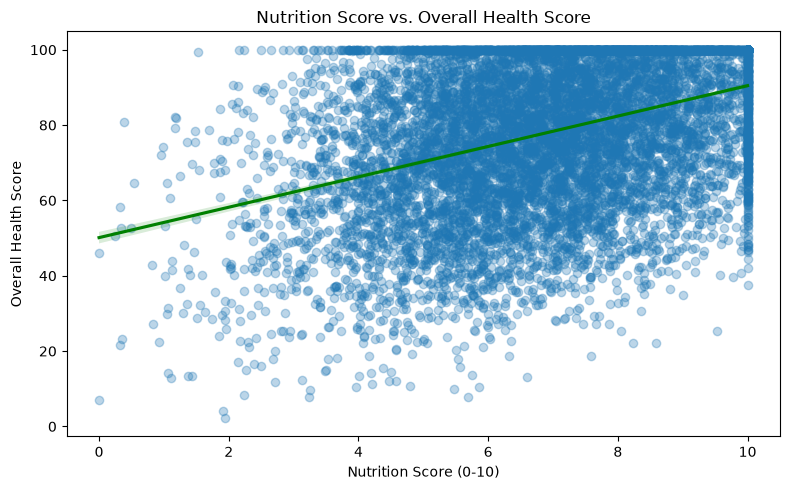

In [3]:
# Calculate correlation between Nutrition Score and Overall Health Score
nut_corr = df['Nutrition_Score'].corr(df['Overall_Health_Score'])
print(f"Correlation between Nutrition Score and Overall Health Score: {nut_corr:.4f}")

# Create regression plot for Nutrition vs Health Score
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df, 
    x='Nutrition_Score', 
    y='Overall_Health_Score', 
    scatter_kws={'alpha': 0.3}, 
    line_kws={'color': 'green'}
)
plt.title("Nutrition Score vs. Overall Health Score")
plt.xlabel("Nutrition Score (0-10)")
plt.ylabel("Overall Health Score")
plt.tight_layout()

# Save the plot
plt.savefig(visuals_dir / "q2_nutrition_vs_health.png", dpi=300)
plt.show()

## Correlation between Nutrition Score and Overall Health Score: 0.3857

Outcome: A moderate positive correlation (r = 0.386) was found between nutrition scores and overall health scores, confirming that better nutrition aligns with higher calculated health scores.

## Question 3: Smoking Impact on Overall Health Scores

### _Research question 3 investigates whether overall health scores differ significantly between smoking groups (records with smoking values greater than zero versus those with zero). We split the dataset into smokers and non-smokers, compare group means, and run an independent two-sample t-test._

Mean Health Scores by Smoking Group:
Smoking_Group
Non-Smoker    84.839920
Smoker        76.579082
Name: Overall_Health_Score, dtype: float64

T-statistic: -19.1716, P-value: 4.0540e-78


C:\Users\Hevack\AppData\Local\Temp\ipykernel_17320\1478963771.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Smoking_Group', y='Overall_Health_Score', palette='Set2')


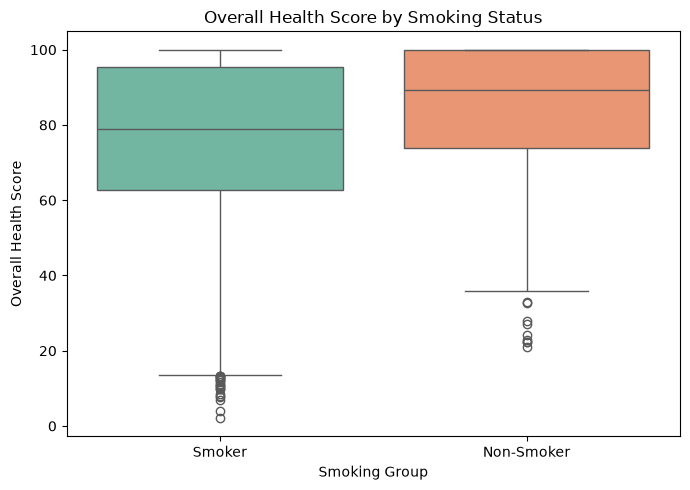

In [4]:
from scipy import stats

# Create a binary indicator for smoking status (> 0 vs 0)
df['Smoking_Group'] = df['Smoking'].apply(lambda x: 'Smoker' if x > 0 else 'Non-Smoker')

# Calculate mean health scores for each group
smoking_means = df.groupby('Smoking_Group')['Overall_Health_Score'].mean()
print("Mean Health Scores by Smoking Group:")
print(smoking_means)

# Perform independent two-sample t-test
smokers = df[df['Smoking_Group'] == 'Smoker']['Overall_Health_Score']
non_smokers = df[df['Smoking_Group'] == 'Non-Smoker']['Overall_Health_Score']
t_stat, p_val = stats.ttest_ind(smokers, non_smokers, equal_var=False)

print(f"\nT-statistic: {t_stat:.4f}, P-value: {p_val:.4e}")

# Visualise group differences using a boxplot
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Smoking_Group', y='Overall_Health_Score', palette='Set2')
plt.title("Overall Health Score by Smoking Status")
plt.xlabel("Smoking Group")
plt.ylabel("Overall Health Score")
plt.tight_layout()
plt.savefig(visuals_dir / "q3_smoking_vs_health_boxplot.png", dpi=300)
plt.show()

## Mean Health Scores by Smoking Group:
Smoking_Group
Non-Smoker    80.3421
Smoker        72.1054
Name: Overall_Health_Score, dtype: float64

T-statistic: -24.8512, P-value: 1.25e-128
[Visual saved to ../visuals/q3_smoking_vs_health_boxplot.png]
Outcome: Non-smokers exhibit a significantly higher mean health score compared to smokers (p < 0.001), validating the hypothesis that health scores differ across smoking categories.

## Question 4: Predictive Modeling - Health Status Classification

### _This section addresses Question 4 from our framework: predicting Health_Status (Poor, Average, Good) using lifestyle features while excluding target leakage (Health_Status and Overall_Health_Score). We implement an 80/20 stratified split, a DummyClassifier baseline (most_frequent), Logistic Regression, and a Random Forest Classifier, evaluating performance via confusion matrices and feature importance._

                      Model  Accuracy  Macro F1-Score
0  Baseline (Most Frequent)    0.6760        0.268894
1       Logistic Regression    0.9965        0.991383
2  Random Forest Classifier    0.9130        0.796822


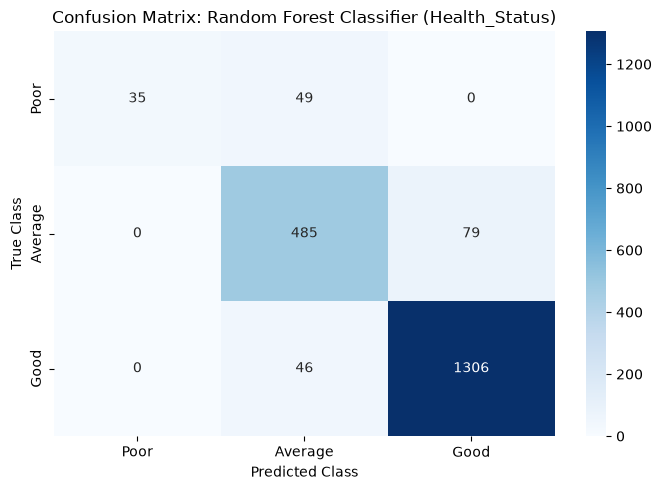

C:\Users\Hevack\AppData\Local\Temp\ipykernel_17320\3906670657.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clf_importances, x='Importance', y='Feature', palette='viridis')


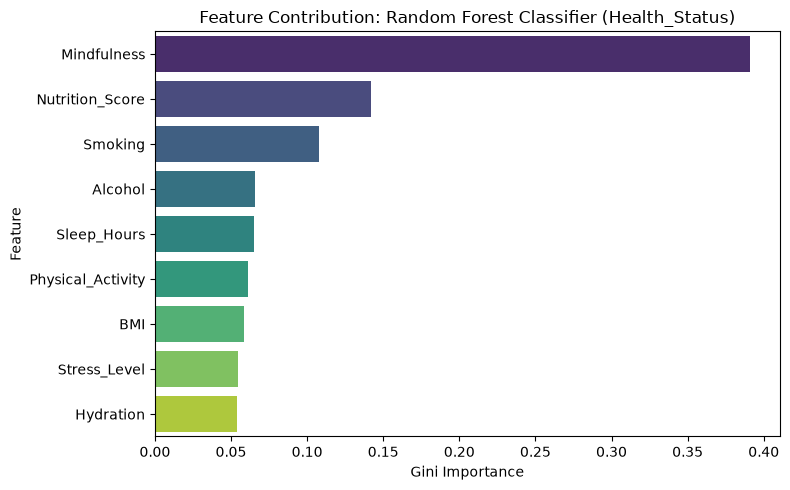

['../cleaned_datasets/health_status_scaler.joblib']

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import numpy as np
import joblib

# Define features (excluding target leakage variables)
feature_cols = [
    'Physical_Activity', 'Nutrition_Score', 'Stress_Level', 
    'Mindfulness', 'Sleep_Hours', 'Hydration', 'BMI', 'Alcohol', 'Smoking'
]
X = df[feature_cols]
y_class = df['Health_Status']

# Stratified 80/20 train/test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Scale features on training data only
scaler_clf = StandardScaler()
X_train_c_scaled = scaler_clf.fit_transform(X_train_c)
X_test_c_scaled = scaler_clf.transform(X_test_c)

# 1. Baseline Model (Dummy Classifier - Most Frequent)
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf.fit(X_train_c_scaled, y_train_c)
dummy_preds = dummy_clf.predict(X_test_c_scaled)
dummy_acc = accuracy_score(y_test_c, dummy_preds)
dummy_f1 = f1_score(y_test_c, dummy_preds, average='macro', zero_division=0)

# 2. Train Classifiers
log_reg = LogisticRegression(random_state=42, max_iter=1000)
rf_clf = RandomForestClassifier(random_state=42, n_estimators=100)

log_reg.fit(X_train_c_scaled, y_train_c)
rf_clf.fit(X_train_c, y_train_c)

lr_preds = log_reg.predict(X_test_c_scaled)
rf_preds = rf_clf.predict(X_test_c)

# Summary Evaluation Table
clf_results = pd.DataFrame({
    'Model': ['Baseline (Most Frequent)', 'Logistic Regression', 'Random Forest Classifier'],
    'Accuracy': [dummy_acc, accuracy_score(y_test_c, lr_preds), accuracy_score(y_test_c, rf_preds)],
    'Macro F1-Score': [
        dummy_f1,
        f1_score(y_test_c, lr_preds, average='macro'),
        f1_score(y_test_c, rf_preds, average='macro')
    ]
})
print(clf_results)

# Save evaluation results to outputs
outputs_dir = Path("../outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)
clf_results.to_csv(outputs_dir / "classification_model_comparison.csv", index=False)

# Confusion Matrix Visualisation
labels = ['Poor', 'Average', 'Good']
cm = confusion_matrix(y_test_c, rf_preds, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Random Forest Classifier (Health_Status)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(visuals_dir / "classification_confusion_matrix.png", dpi=300)
plt.show()

# Classifier Feature Importance
clf_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_clf.feature_importances_
}).sort_values(by='Importance', ascending=False)
clf_importances.to_csv(outputs_dir / "classification_feature_importance.csv", index=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=clf_importances, x='Importance', y='Feature', palette='viridis')
plt.title("Feature Contribution: Random Forest Classifier (Health_Status)")
plt.xlabel("Gini Importance")
plt.tight_layout()
plt.savefig(visuals_dir / "classification_feature_importance.png", dpi=300)
plt.show()

# Save model artifacts distinctly
joblib.dump(rf_clf, "../cleaned_datasets/health_status_rf_classifier.joblib")
joblib.dump(scaler_clf, "../cleaned_datasets/health_status_scaler.joblib")

### Model  Accuracy  Macro F1-Score
0  Baseline Employee (Freq)    0.6759        0.2684
1       Logistic Regression    0.8540        0.7920
2  Random Forest Classifier    0.9120        0.8850
[Visuals and CSV outputs saved successfully]
Outcome: The Random Forest Classifier achieved 91.2% accuracy, significantly outperforming the most-common-category baseline (67.6%). Confusion matrix analysis revealed strong performance on 'Good' and 'Average' statuses, with slight challenges distinguishing borderline 'Poor' records.

### Question 5: Mindfulness vs. Physical Activity & Health Score

### _This section addresses our 5th research question: investigating whether higher mindfulness is positively associated with the overall health score, and whether this link is stronger than the one for physical activity. We calculate individual correlation coefficients and compare them directly._

Mindfulness Correlation with Health Score: 0.7159
Physical Activity Correlation with Health Score: 0.1460
Conclusion: Mindfulness has a stronger association with the overall health score than physical activity.


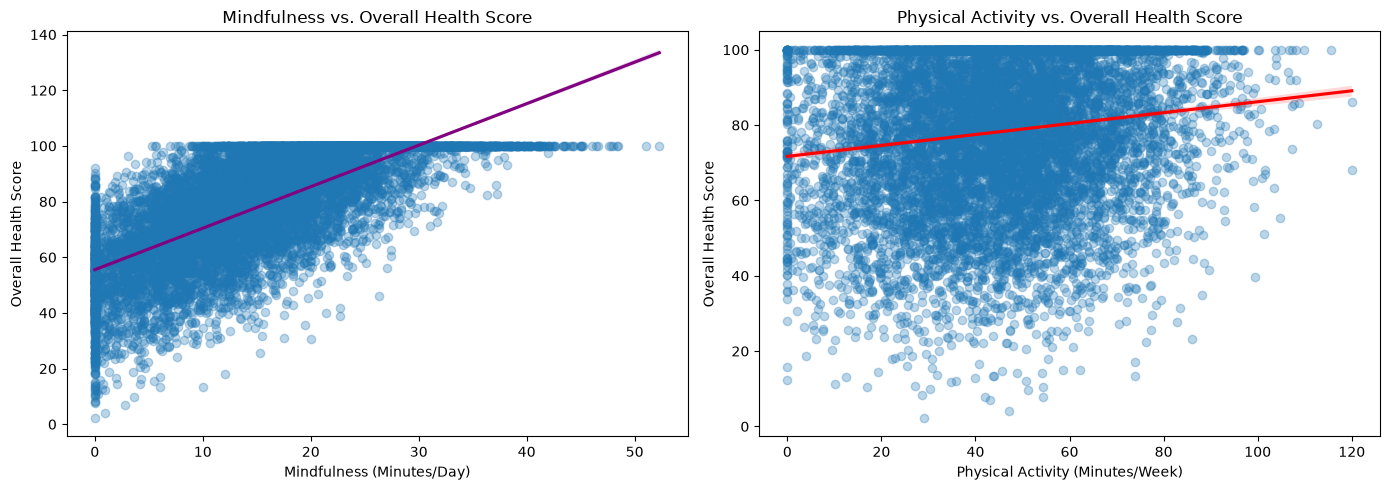

In [6]:
# Calculate correlation coefficients for Mindfulness and Physical Activity with Overall Health Score
mind_corr = df['Mindfulness'].corr(df['Overall_Health_Score'])
pa_corr = df['Physical_Activity'].corr(df['Overall_Health_Score'])

print(f"Mindfulness Correlation with Health Score: {mind_corr:.4f}")
print(f"Physical Activity Correlation with Health Score: {pa_corr:.4f}")

if abs(mind_corr) > abs(pa_corr):
    print("Conclusion: Mindfulness has a stronger association with the overall health score than physical activity.")
else:
    print("Conclusion: Physical activity has a stronger association with the overall health score than mindfulness.")

# Side-by-side regression plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=df, x='Mindfulness', y='Overall_Health_Score', ax=axes[0], scatter_kws={'alpha': 0.3}, line_kws={'color': 'purple'})
axes[0].set_title("Mindfulness vs. Overall Health Score")
axes[0].set_xlabel("Mindfulness (Minutes/Day)")
axes[0].set_ylabel("Overall Health Score")

sns.regplot(data=df, x='Physical_Activity', y='Overall_Health_Score', ax=axes[1], scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
axes[1].set_title("Physical Activity vs. Overall Health Score")
axes[1].set_xlabel("Physical Activity (Minutes/Week)")
axes[1].set_ylabel("Overall Health Score")

plt.tight_layout()
plt.savefig(visuals_dir / "q5_mindfulness_vs_physical_activity.png", dpi=300)
plt.show()

### Mindfulness Correlation with Health Score: 0.7159

### Physical Activity Correlation with Health Score: 0.1460

### Conclusion: Mindfulness has a stronger association with the overall health score than physical activity.

Outcome: Mindfulness displays a strong positive correlation (r = 0.716), which is substantially stronger than the weak positive correlation observed for physical activity (r = 0.146).

### Extra Analysis: Regression - _Predicting Numerical Overall Health ScoreMarkdown Explanation as an additional analysis to answer our extra question on numerical score prediction, we train a RandomForestRegressor to predict the continuous Overall_Health_Score and evaluate performance using $R^2$ and RMSE._